## Imports and dataset loading

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

data_directory = next(
    (
        path
        for path in (Path("datasets"), Path("."))
        if (path / "u.data").is_file() and (path / "Movie_Id_Titles.txt").is_file()
    ),
    None,
)

if data_directory is None:
    raise FileNotFoundError(
        "Dataset files were not found. Place u.data and Movie_Id_Titles.txt "
        "inside a datasets folder beside this notebook."
    )

ratings_path = data_directory / "u.data"
titles_path = data_directory / "Movie_Id_Titles.txt"

column_names = ["user_id", "item_id", "rating", "timestamp"]

ratings_data = pd.read_csv(
    ratings_path,
    sep="\t",
    names=column_names,
    header=None,
)

movie_titles = pd.read_csv(titles_path)

required_title_columns = {"item_id", "title"}
if not required_title_columns.issubset(movie_titles.columns):
    raise ValueError(
        "Movie_Id_Titles.txt must contain item_id and title columns."
    )

ratings_data.head()

,user_id,item_id,rating,timestamp
0,0,50,5,881250949
1,0,172,5,881250949
2,0,133,1,881250949
3,196,242,3,881250949
4,186,302,3,891717742


## Dataset overview

In [3]:
print(f"Ratings records: {len(ratings_data):,}")
print(f"Unique users: {ratings_data['user_id'].nunique():,}")
print(f"Unique movies rated: {ratings_data['item_id'].nunique():,}")
print(f"Movie titles: {movie_titles['item_id'].nunique():,}")

display(ratings_data.head())
display(movie_titles.head())

Ratings records: 100,003
Unique users: 944
Unique movies rated: 1,682
Movie titles: 1,682


,user_id,item_id,rating,timestamp
0,0,50,5,881250949
1,0,172,5,881250949
2,0,133,1,881250949
3,196,242,3,881250949
4,186,302,3,891717742


,item_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


## Combine ratings and movie titles

In [4]:
df = ratings_data.merge(
    movie_titles[["item_id", "title"]],
    on="item_id",
    how="inner",
    validate="many_to_one",
)

df = df.dropna(subset=["title", "rating"])

print(f"Combined records: {len(df):,}")
display(df.head(10))

Combined records: 100,003


,user_id,item_id,rating,timestamp,title
0,0,50,5,881250949,Star Wars (1977)
1,0,172,5,881250949,"Empire Strikes Back, The (1980)"
2,0,133,1,881250949,Gone with the Wind (1939)
3,196,242,3,881250949,Kolya (1996)
4,186,302,3,891717742,L.A. Confidential (1997)
5,22,377,1,878887116,Heavyweights (1994)
6,244,51,2,880606923,Legends of the Fall (1994)
7,166,346,1,886397596,Jackie Brown (1997)
8,298,474,4,884182806,Dr. Strangelove or: How I Learned to Stop Worr...
9,115,265,2,881171488,"Hunt for Red October, The (1990)"


## Explore movie ratings

In [5]:
ratings = (
    df.groupby("title")["rating"]
    .agg(rating="mean", num_of_ratings="count")
    .sort_values("num_of_ratings", ascending=False)
)

display(ratings.head(10))

,rating,num_of_ratings
title,,
Star Wars (1977),4.359589,584
Contact (1997),3.803536,509
Fargo (1996),4.155512,508
Return of the Jedi (1983),4.007890,507
Liar Liar (1997),3.156701,485
"English Patient, The (1996)",3.656965,481
Scream (1996),3.441423,478
Toy Story (1995),3.878319,452
Air Force One (1997),3.631090,431


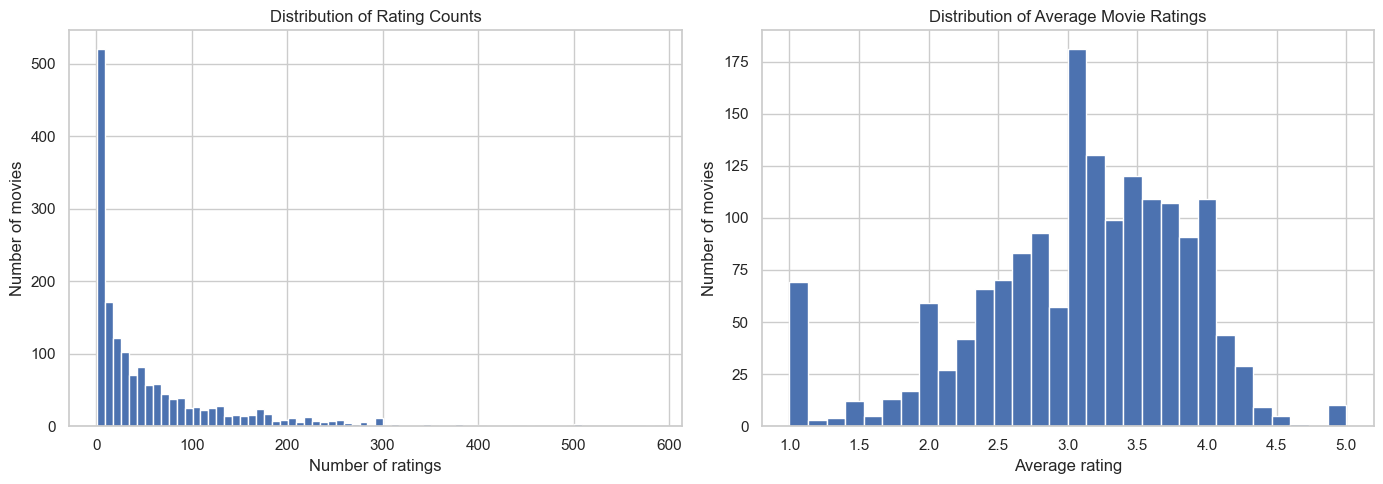

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ratings["num_of_ratings"].hist(bins=70, ax=axes[0])
axes[0].set_title("Distribution of Rating Counts")
axes[0].set_xlabel("Number of ratings")
axes[0].set_ylabel("Number of movies")

ratings["rating"].hist(bins=30, ax=axes[1])
axes[1].set_title("Distribution of Average Movie Ratings")
axes[1].set_xlabel("Average rating")
axes[1].set_ylabel("Number of movies")

plt.tight_layout()
plt.show()

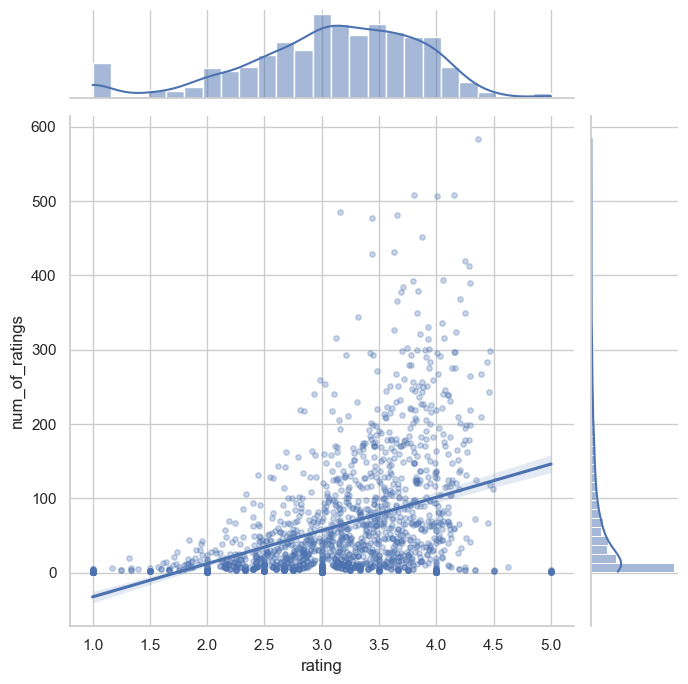

In [13]:
sns.jointplot(
    data=ratings,
    x="rating",
    y="num_of_ratings",
    kind="reg",
    height=7,
    joint_kws={"scatter_kws": {"alpha": 0.3, "s": 15}}
)
plt.show()

## Create the user-movie rating matrix

In [8]:
moviemat = df.pivot_table(
    index="user_id",
    columns="title",
    values="rating",
)

display(moviemat.iloc[:5, :10])

title,'Til There Was You (1997),1-900 (1994),101 Dalmatians (1996),12 Angry Men (1957),187 (1997),2 Days in the Valley (1996),"20,000 Leagues Under the Sea (1954)",2001: A Space Odyssey (1968),3 Ninjas: High Noon At Mega Mountain (1998),"39 Steps, The (1935)"
user_id,,,,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,2.0,5.0,NaN,NaN,3.0,4.0,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN
3,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Find movies similar to a selected movie

In [9]:
def get_similar_movies(movie_title, min_ratings=100):
    if movie_title not in moviemat.columns:
        raise ValueError(f"Movie not found in the rating matrix: {movie_title}")

    target_ratings = moviemat[movie_title]
    correlations = moviemat.corrwith(target_ratings)

    recommendations = pd.DataFrame(
        {"correlation": correlations}
    ).join(ratings["num_of_ratings"])

    recommendations = recommendations.dropna()
    recommendations = recommendations[
        recommendations["num_of_ratings"] >= min_ratings
    ]

    recommendations = recommendations.drop(index=movie_title, errors="ignore")

    return recommendations.sort_values(
        "correlation",
        ascending=False,
    )

## Star Wars recommendations

In [10]:
star_wars_recommendations = get_similar_movies(
    "Star Wars (1977)",
    min_ratings=100,
)

display(star_wars_recommendations.head(10))

C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


,correlation,num_of_ratings
title,,
"Empire Strikes Back, The (1980)",0.748353,368
Return of the Jedi (1983),0.672556,507
Raiders of the Lost Ark (1981),0.536117,420
Austin Powers: International Man of Mystery (1997),0.377433,130
"Sting, The (1973)",0.367538,241
Indiana Jones and the Last Crusade (1989),0.350107,331
Pinocchio (1940),0.347868,101
"Frighteners, The (1996)",0.332729,115
L.A. Confidential (1997),0.319065,297


## Liar Liar recommendations

In [11]:
liar_liar_recommendations = get_similar_movies(
    "Liar Liar (1997)",
    min_ratings=100,
)

display(liar_liar_recommendations.head(10))

C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,correlation,num_of_ratings
title,,
Batman Forever (1995),0.516968,114
"Mask, The (1994)",0.484650,129
Down Periscope (1996),0.472681,101
Con Air (1997),0.469828,137
Pretty Woman (1990),0.469790,164
101 Dalmatians (1996),0.469765,109
Michael (1996),0.442022,119
Waterworld (1995),0.438405,102
Indiana Jones and the Last Crusade (1989),0.414427,331


## Try another movie

In [12]:
movie_title = "Toy Story (1995)"
custom_recommendations = get_similar_movies(
    movie_title,
    min_ratings=100,
)

display(custom_recommendations.head(10))

C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2897: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Noyon\.conda\envs\ml\lib\site-packages\numpy\lib\function_base.py:2898: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,correlation,num_of_ratings
title,,
"Craft, The (1996)",0.549100,104
Down Periscope (1996),0.457995,101
Miracle on 34th Street (1994),0.456291,101
G.I. Jane (1997),0.454756,175
Amistad (1997),0.449915,124
Beauty and the Beast (1991),0.442960,202
"Mask, The (1994)",0.432855,129
Cinderella (1950),0.428372,129
That Thing You Do! (1996),0.427936,176
